In [1]:
# imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
df = pd.DataFrame()

df = pd.read_csv('../data/processed/masskara/analysis/master.csv')

df.head(1)

,date_collected,trend_search_score,flight_fest_min_price,flight_fest_max_price,flight_fest_median_price,flight_fest_mean_price,flight_fest_quote_count,flight_rolling_min_price,flight_rolling_max_price,flight_rolling_median_price,...,hotel_rolling_quote_count,flight_price_premium,hotel_price_premium,trend_velocity_7d,trend_score_lag_1d,trend_score_lag_2d,trend_score_lag_3d,flight_median_change_1d,hotel_median_change_1d,days_to_festival
0,2026-09-02,82,1936,2731,2234.0,2317.230769,13,2900,5643,3684.0,...,20,0.606406,1.122834,NaN,NaN,NaN,NaN,NaN,NaN,37


In [3]:
# 1. Clean data for the pair to test
analysis_df = df[['trend_search_score', 'flight_fest_median_price', 'days_to_festival']].dropna()

In [4]:
# 2. Statistical Correlation & p-value
r_val, p_val = stats.pearsonr(analysis_df['trend_search_score'], analysis_df['flight_fest_median_price'])

print(f"Pearson Correlation (r): {r_val:.3f}")
print(f"p-value: {p_val:.4e}")

Pearson Correlation (r): 0.427
p-value: 1.0576e-02


In [5]:
# 3. A/B Group Comparison (High vs Low Search Trend)
median_trend = analysis_df['trend_search_score'].median()
analysis_df['trend_group'] = np.where(
    analysis_df['trend_search_score'] >= median_trend, 
    'High Trend (>= Median)', 
    'Low Trend (< Median)'
)

group_summary = analysis_df.groupby('trend_group')['flight_fest_median_price'].agg(['count', 'mean', 'median', 'std'])
print("\n--- Group Comparison Summary ---")
print(group_summary)


--- Group Comparison Summary ---
                        count         mean  median          std
trend_group                                                    
High Trend (>= Median)     20  3225.275000  2695.0  1355.251787
Low Trend (< Median)       15  2596.866667  2695.0   125.453957


In [6]:
# Optional: Two-sample t-test between high and low groups
high_prices = analysis_df[analysis_df['trend_group'] == 'High Trend (>= Median)']['flight_fest_median_price']
low_prices = analysis_df[analysis_df['trend_group'] == 'Low Trend (< Median)']['flight_fest_median_price']
t_stat, t_pval = stats.ttest_ind(high_prices, low_prices, equal_var=False)
print(f"\nWelch's t-test p-value between groups: {t_pval:.4e}")


Welch's t-test p-value between groups: 5.2846e-02


C:\Users\gratu\AppData\Local\Temp\ipykernel_6532\4102229785.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


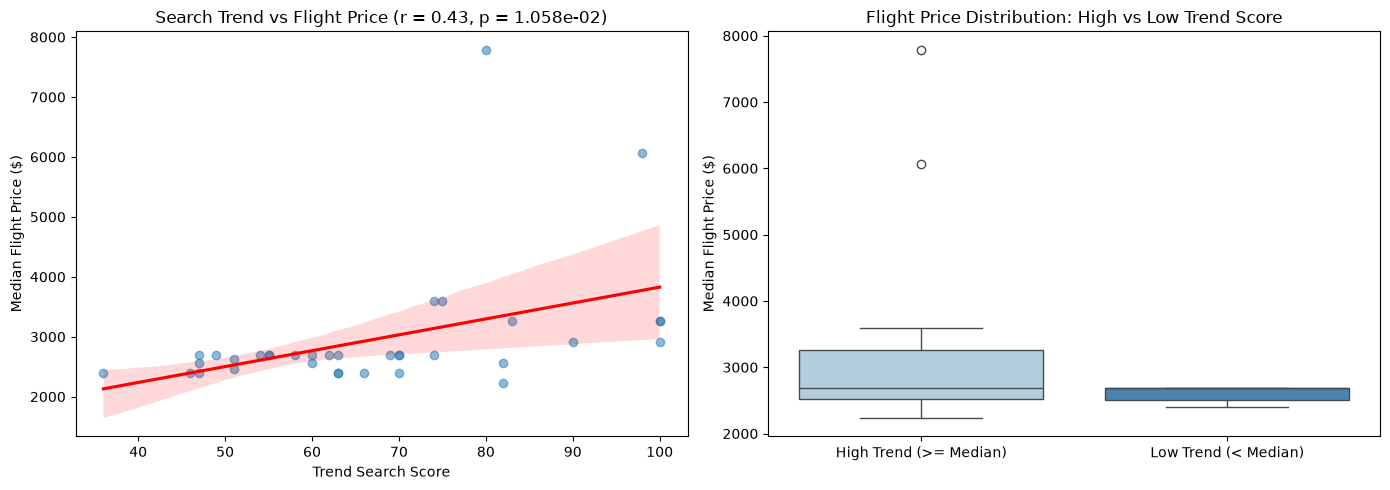

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Scatter plot with regression line
sns.regplot(
    data=analysis_df, 
    x='trend_search_score', 
    y='flight_fest_median_price', 
    ax=axes[0],
    scatter_kws={'alpha': 0.5},
    line_kws={'color': 'red'}
)
axes[0].set_title(f"Search Trend vs Flight Price (r = {r_val:.2f}, p = {p_val:.3e})")
axes[0].set_xlabel("Trend Search Score")
axes[0].set_ylabel("Median Flight Price ($)")

# Plot 2: Boxplot comparing High vs Low Trend groups
sns.boxplot(
    data=analysis_df, 
    x='trend_group', 
    y='flight_fest_median_price', 
    ax=axes[1],
    palette='Blues'
)
axes[1].set_title("Flight Price Distribution: High vs Low Trend Score")
axes[1].set_xlabel("")
axes[1].set_ylabel("Median Flight Price ($)")

plt.tight_layout()
plt.show()

## Inference Check

### Relationship or Comparison
I am checking whether dates with high search interest (`trend_search_score >= median`) have higher flight prices (`flight_fest_median_price`) than dates with low search interest (`< median`).

### What the Data Shows
- **Correlation:** Pearson's $r = 0.427$ with $p = 0.0106$, which initially appears to show a statistically significant moderate positive relationship.
- **Group Comparison:**
  - **High Trend (n = 20):** Mean = $3,225.28 | Median = $2,695.00 | Std = $1,355.25
  - **Low Trend (n = 15):** Mean = $2,596.87 | Median = $2,695.00 | Std = $125.45
- **Hypothesis Test:** Welch's two-sample t-test yields $p = 0.0528$. Because $p > 0.05$, there is no statistically significant difference in mean flight prices between high and low search trend periods at the standard 5% significance level.
- **Identical Medians:** Both groups have the exact same median price ($2,695.00).

### What I Can Say Carefully
- Typical flight prices do not change based on search volume; the median flight price ($2,695) is completely unaffected by whether search trend scores are high or low.
- Higher search volume is associated with much greater price variance and volatility (std of $1,355 vs $125), driven by two isolated spikes ($6,066 and $7,794).
- The linear correlation ($r = 0.427$) is heavily inflated by these two extreme values rather than an across-the-board increase in fares.

### What I Cannot Conclude
- **No Causal Link:** We cannot conclude that increased search traffic causes flight prices to rise.
- **No Robust Shift:** We cannot claim that flights are generally more expensive during high-interest periods, since the group t-test failed to reach statistical significance ($p = 0.0528$) and the medians are identical.
- **Confounding Factors:** External variables like `days_to_festival` and seat inventory are unaddressed. Urgency near festival dates likely causes both the spike in search interest and the scarcity of standard seats.